# Frozen PANNs: Gaussian-to-Recorded-Noise Transfer

## tl;dr

Gaussian training exposure raises the matched linear head's Gaussian accuracy from **69.85% to 83.92%**. Across six fixed recorded-background conditions, accuracy changes from **89.07% to 90.12%**: **+1.05 percentage points**, conditional 95% source-bootstrap interval **[−0.54, +2.59]**. The recorded-noise benefit remains uncertain. Clean accuracy changes from **91.21% to 91.96%**; its difference is also uncertain.

Both new heads converged on Colab Tesla T4, with the PANNs encoder frozen. Two head fits, zero encoder fits, no test-WAV reads. The historical head remains unchanged. The completed evidence supports a matched-Gaussian improvement, without establishing a general recorded-noise benefit. Saved-result analysis is the default; repeating model computation is optional.

## Context & Methods

**Question:** Does Gaussian exposure during linear-head training improve recognition under recorded backgrounds excluded from training?

- Frozen official `Cnn14_16k`; 2,048 features, 50 outputs; no encoder training.
- Identical clean-fitted scaler and L2 multinomial logistic regression: C=1, L-BFGS, 3,000 maximum iterations, tolerance 1e-6.
- Training: 1,200 original clips. Mixed head: each clean embedding weight 0.5; two waveform-noise variants each weight 0.25, SNR drawn uniformly from 10–30 dB. Total weight remains 1,200, matching effective regularization.
- Development: 398 clips from 295 recording sources. No test WAV is read. All official folds have historical exposure.
- Primary: adapted-minus-clean accuracy, averaged equally over six fixed recorded-noise conditions within each target, then across targets. Paired 95% source-bootstrap interval, 4,000 resamples, conditional on the fixed heads and backgrounds.

### Key Assumptions

Every target is crossed with river, hallway and car backgrounds, using channel 1 at 30–35 s and 150–155 s. Backgrounds were selected by metadata-based diversity before predictions; no listening-based eligibility claim is made. The task is classification of the **designated foreground recording**, not multi-label annotation of the entire mixture. Backgrounds may contain recognizable events. Full-window target power defines added-interference SNR; the original audio is not guaranteed noise-free. No clipping, normalization or outcome-based exclusion is applied.

Sources: [ESC-50](https://github.com/karolpiczak/ESC-50), [PANNs](https://github.com/qiuqiangkong/audioset_tagging_cnn), [DEMAND](https://zenodo.org/records/1227121), [weighted logistic objective](https://scikit-learn.org/stable/modules/linear_model.html#multinomial-case). DEMAND recordings are CC BY-SA 3.0. No raw audio is distributed here.

### Locate the project and select execution mode

In [ ]:
from pathlib import Path
import os, sys, json, subprocess
RUN_EXPERIMENT = False
candidates = [Path(os.environ.get("ESC50_PROJECT_ROOT", ".")), Path.cwd(), Path.cwd().parent, Path("/content/esc50_project")]
ROOT = next((p.resolve() for p in candidates if (p/"src/esc50_sound").is_dir()), None)
if ROOT is None:
    ROOT = Path("/content/esc50_project")
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/Richardafcs/esc-50-sound-classification.git", str(ROOT)], check=True)
DATA = ROOT/"reports/noise_transfer_20261106"
ASSETS = Path("/content/esc50_noise_assets")
print("Mode:", "Repeat fixed experiment" if RUN_EXPERIMENT else "Analyze completed evidence")

Mode: Analyze completed evidence


### Optional fresh-runtime model computation
Enable `RUN_EXPERIMENT` only to repeat the fixed two-head experiment on a GPU runtime. Completed results are reused. This cell downloads official inputs and extracts only train/development target WAVs and channel 1 of each background.

In [ ]:
if RUN_EXPERIMENT:
    root=ASSETS; root.mkdir(exist_ok=True)
    from concurrent.futures import ThreadPoolExecutor
    import zipfile
    subprocess.run([sys.executable,'-m','pip','install','-q','torchlibrosa==0.1.0','librosa==0.11.0','soundfile>=0.13','scikit-learn==1.6.1','pandas>=2.2','matplotlib>=3.9','nbformat','nbconvert'],check=True,capture_output=True,timeout=360)
    items=[('Cnn14_16k_mAP=0.438.pth','https://zenodo.org/records/3987831/files/Cnn14_16k_mAP%3D0.438.pth?download=1'),('ESC-50.zip','https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master')]
    items += [(name+'_16k.zip','https://zenodo.org/records/1227121/files/'+name+'_16k.zip?download=1') for name in ('NRIVER','OHALLWAY','TCAR')]
    def acquire(item):
     name,url=item;path=root/name
     if not path.exists():
      part=path.with_suffix(path.suffix+'.part')
      subprocess.run(['curl','-fsSL','--retry','2','--max-time','900','-o',str(part),url],check=True,capture_output=True,timeout=950)
      part.replace(path)
     print('Official input ready:',name,flush=True)
    with ThreadPoolExecutor(max_workers=3) as workers:list(workers.map(acquire,items))
    sys.path.insert(0,str(ROOT/'src'))
    from esc50_sound.data import read_metadata,split_rows
    rows=read_metadata(ROOT/'data/ESC-50');roles=split_rows(rows)
    names={rows[i]['filename'] for role in ('train','validation') for i in roles[role]}
    audio=root/'ESC-50/audio';audio.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(root/'ESC-50.zip') as z:
     for member in z.infolist():
      if '/audio/' in member.filename and Path(member.filename).name in names:
       (audio/Path(member.filename).name).write_bytes(z.read(member))
    print('Extracted train/development WAVs:',len(list(audio.glob('*.wav'))),'test WAVs extracted: 0',flush=True)
    for name in ('NRIVER','OHALLWAY','TCAR'):
     with zipfile.ZipFile(root/(name+'_16k.zip')) as z:
      candidates=[n for n in z.namelist() if n.lower().endswith('/ch01.wav')]
      if len(candidates)!=1:raise ValueError((name,candidates))
      (root/(name+'_ch01.wav')).write_bytes(z.read(candidates[0]))
    print('NOISE_TRANSFER_ASSETS_READY',flush=True)
    
    repo=ROOT/"official_panns"
    if not repo.exists():
        subprocess.run(["git","clone","--depth","1","https://github.com/qiuqiangkong/audioset_tagging_cnn.git",str(repo)],check=True)
    # A fresh checkout can rebuild clean feature caches with the original extraction runner.
    cache=ROOT/"results/embedding_cache"
    if not (cache/"train_embeddings.npz").exists():
        sys.path.insert(0,str(ROOT/"scripts"))
        import numpy as np
        import torch
        from run_transfer_followup import load_panns
        from run_panns_linear_probe import extract, save_features
        cache.mkdir(parents=True,exist_ok=True)
        encoder=load_panns(repo,ASSETS/"Cnn14_16k_mAP=0.438.pth",torch.device("cuda"))
        for role,filename in [("train","train_embeddings.npz"),("validation","val_embeddings.npz")]:
            selected=sorted([rows[i] for i in roles[role]],key=lambda r:r["filename"])
            features,_=extract(encoder,selected,ASSETS/"ESC-50/audio",torch.device("cuda"),role)
            save_features(cache/filename,features,selected)
        del encoder
    
    subprocess.run([sys.executable,str(ROOT/"scripts/run_noise_transfer.py"),"--assets",str(ASSETS),"--output",str(DATA),"--device","cuda"],check=True)
else:
    print("No new fits or inference requested.")

No new fits or inference requested.


## Data
The protocol was saved before new head fits or evaluation predictions. Six backgrounds × 398 targets gives 2,388 recorded-noise target/condition pairs; these are not 2,388 independent target recordings.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
summary = json.loads((DATA/"summary.json").read_text())
protocol = json.loads((DATA/"protocol.json").read_text())
metrics = pd.read_csv(DATA/"metrics.csv")
effects = pd.read_csv(DATA/"paired_effects.csv")
transitions = pd.read_csv(DATA/"transitions.csv")
predictions = pd.read_csv(DATA/"predictions.csv")
backgrounds = pd.read_csv(DATA/"background_segments.csv")
plt.rcParams.update({"figure.dpi":120,"font.size":11,"axes.spines.top":False,"axes.spines.right":False})
COLORS={"clean_refit":"#28668e","gaussian_adapted":"#c87527","historical_lr":"#777777"}
LABELS={"clean_refit":"Clean refit","gaussian_adapted":"Gaussian-adapted","historical_lr":"Historical LR"}
display(backgrounds[["environment","channel","start_seconds","end_seconds","segment_rms"]])
display(pd.read_csv(DATA/"head_fits.csv").round(3))
print("GPU:",summary["environment"]["gpu"],"| New head fits:",summary["new_head_fits"],"| Encoder fits:",summary["encoder_fits"])
print("Compute:",round(summary["compute_seconds"],2),"seconds; setup/downloads excluded.")

,environment,channel,start_seconds,end_seconds,segment_rms
0,NRIVER,ch01,30,35,0.002090
1,NRIVER,ch01,150,155,0.002237
2,OHALLWAY,ch01,30,35,0.001295
3,OHALLWAY,ch01,150,155,0.002531
4,TCAR,ch01,30,35,0.094626
5,TCAR,ch01,150,155,0.081502


,model,rows,total_weight,iterations,converged,seconds
0,clean_refit,1200,1200.0,137,True,13.353
1,gaussian_adapted,3600,1200.0,435,True,73.298


GPU: Tesla T4 | New head fits: 2 | Encoder fits: 0
Compute: 174.9 seconds; setup/downloads excluded.


## Results
### Primary effect and clean-performance trade-off

In [ ]:
primary=effects.set_index("condition").loc["recorded_mean_primary"]
clean=effects.set_index("condition").loc["clean"]
gaussian=effects.set_index("condition").loc["historical_shared_gaussian10"]
display(Markdown(f"**Recorded-background accuracy change: {primary.delta_pp:+.2f} pp**, conditional 95% source-bootstrap interval **[{primary.low_pp:+.2f}, {primary.high_pp:+.2f}]**. Clean change: **{clean.delta_pp:+.2f} pp**; Gaussian change: **{gaussian.delta_pp:+.2f} pp**."))
recorded=pd.read_csv(DATA/"recorded_means.csv")
display(recorded[["model","accuracy","macro_f1"]].assign(accuracy=lambda d:100*d.accuracy,macro_f1=lambda d:100*d.macro_f1).rename(columns={"accuracy":"Mean accuracy (%)","macro_f1":"Mean per-condition macro-F1 (%)"}).round(2))
print("Historical reference correct:",summary["historical_clean_correct"],"clean;",summary["historical_gaussian_correct"],"Gaussian.")

**Recorded-background accuracy change: +1.05 pp**, conditional 95% source-bootstrap interval **[-0.54, +2.59]**. Clean change: **+0.75 pp**; Gaussian change: **+14.07 pp**.

,model,Mean accuracy (%),Mean per-condition macro-F1 (%)
0,clean_refit,89.07,89.15
1,gaussian_adapted,90.12,90.21
2,historical_lr,89.07,89.15


Historical reference correct: 363 clean; 278 Gaussian.


### Accuracy by interference environment

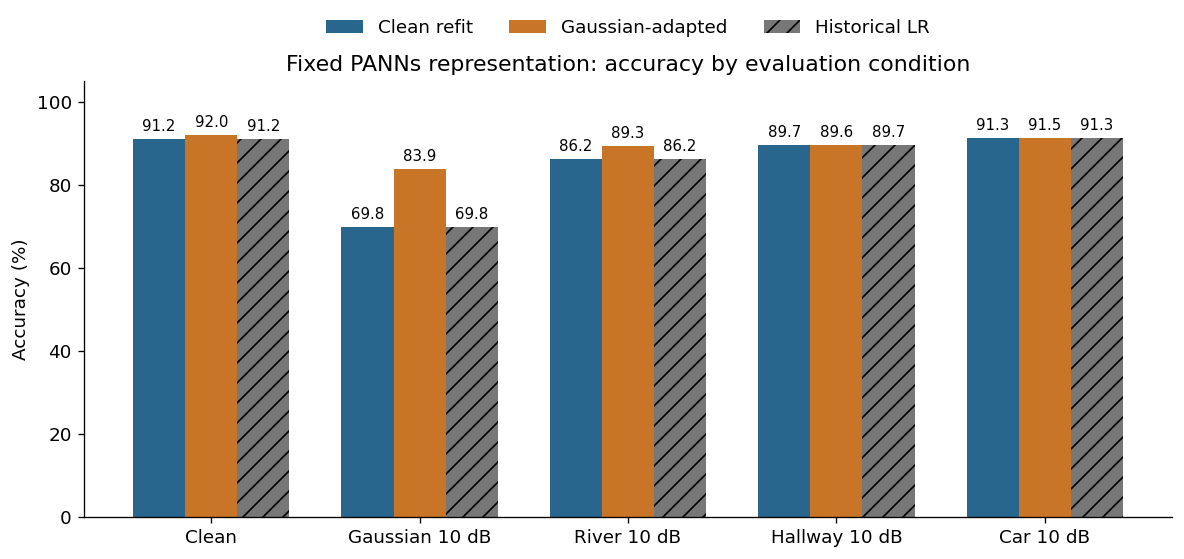

In [ ]:
order=["clean","historical_shared_gaussian10","NRIVER","OHALLWAY","TCAR"]
short={"clean":"Clean","historical_shared_gaussian10":"Gaussian 10 dB","NRIVER":"River 10 dB","OHALLWAY":"Hallway 10 dB","TCAR":"Car 10 dB"}
plot_data=metrics.copy()
plot_data["group"]=plot_data.condition.map(lambda c: next((e for e in ["NRIVER","OHALLWAY","TCAR"] if c.startswith(e)),c))
table=plot_data.groupby(["model","group"])["accuracy"].mean().unstack().reindex(columns=order)
fig,ax=plt.subplots(figsize=(10,4.8));x=np.arange(len(order));width=.25
for i,model in enumerate(["clean_refit","gaussian_adapted","historical_lr"]):
    bars=ax.bar(x+(i-1)*width,100*table.loc[model],width,label=LABELS[model],color=COLORS[model],hatch="//" if model=="historical_lr" else None)
    ax.bar_label(bars,fmt="%.1f",padding=3,fontsize=9)
ax.set(xticks=x,xticklabels=[short[c] for c in order],ylim=(0,105),ylabel="Accuracy (%)",title="Fixed PANNs representation: accuracy by evaluation condition")
ax.legend(loc="upper center",bbox_to_anchor=(.5,1.18),ncol=3,frameon=False)
fig.tight_layout();fig.savefig(DATA/"accuracy_by_environment.png",dpi=180,bbox_inches="tight");plt.show()

Each recorded environment averages its two fixed segments. Bars describe fixed systems and conditions; the paired difference intervals below address target-source variation.

### Paired accuracy differences

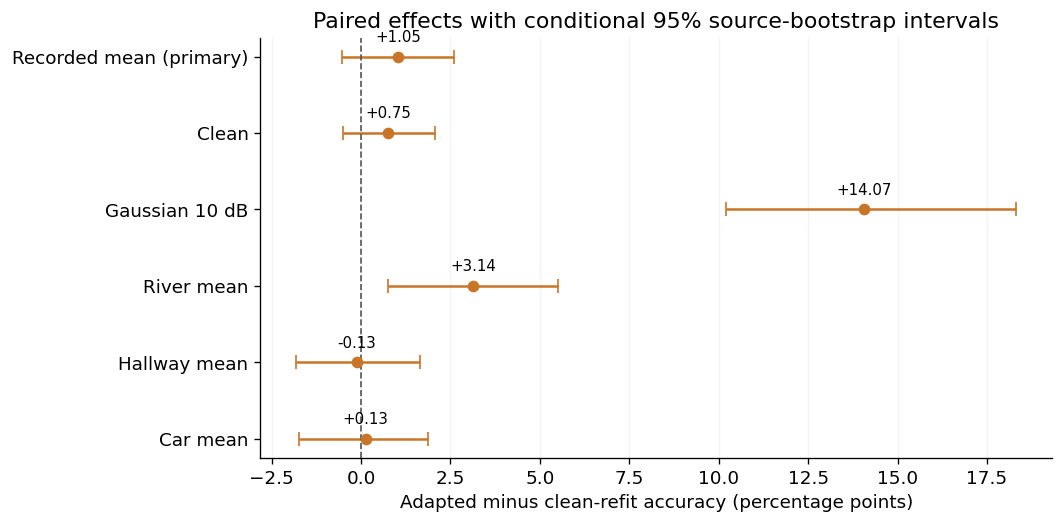

,delta_pp,low_pp,high_pp
condition,,,
recorded_mean_primary,1.05,-0.54,2.59
clean,0.75,-0.51,2.06
historical_shared_gaussian10,14.07,10.20,18.32
NRIVER_mean,3.14,0.76,5.50
OHALLWAY_mean,-0.13,-1.81,1.64
TCAR_mean,0.13,-1.72,1.88


In [ ]:
selected=["recorded_mean_primary","clean","historical_shared_gaussian10","NRIVER_mean","OHALLWAY_mean","TCAR_mean"]
labels=["Recorded mean (primary)","Clean","Gaussian 10 dB","River mean","Hallway mean","Car mean"]
frame=effects.set_index("condition").loc[selected]
fig,ax=plt.subplots(figsize=(9,4.5));pos=np.arange(len(frame))
ax.errorbar(frame.delta_pp,pos,xerr=np.vstack([frame.delta_pp-frame.low_pp,frame.high_pp-frame.delta_pp]),fmt="o",color=COLORS["gaussian_adapted"],capsize=4)
ax.axvline(0,color="#555555",linewidth=1,linestyle="--")
ax.set(yticks=pos,yticklabels=labels,xlabel="Adapted minus clean-refit accuracy (percentage points)",title="Paired effects with conditional 95% source-bootstrap intervals")
ax.invert_yaxis();ax.grid(axis="x",alpha=.15)
for j,row in enumerate(frame.itertuples()):ax.annotate(f"{row.delta_pp:+.2f}",(row.delta_pp,j),xytext=(0,9),textcoords="offset points",ha="center",fontsize=9)
fig.tight_layout();fig.savefig(DATA/"paired_accuracy_effects.png",dpi=180,bbox_inches="tight");plt.show()
display(frame[["delta_pp","low_pp","high_pp"]].round(2))

Intervals resample the 295 original recording sources and retain their clips, after averaging fixed recorded-noise differences within each clip. They do not quantify future-head training variation or uncertainty across all possible noise environments. Secondary intervals are descriptive and unadjusted.

### Repairs and new errors

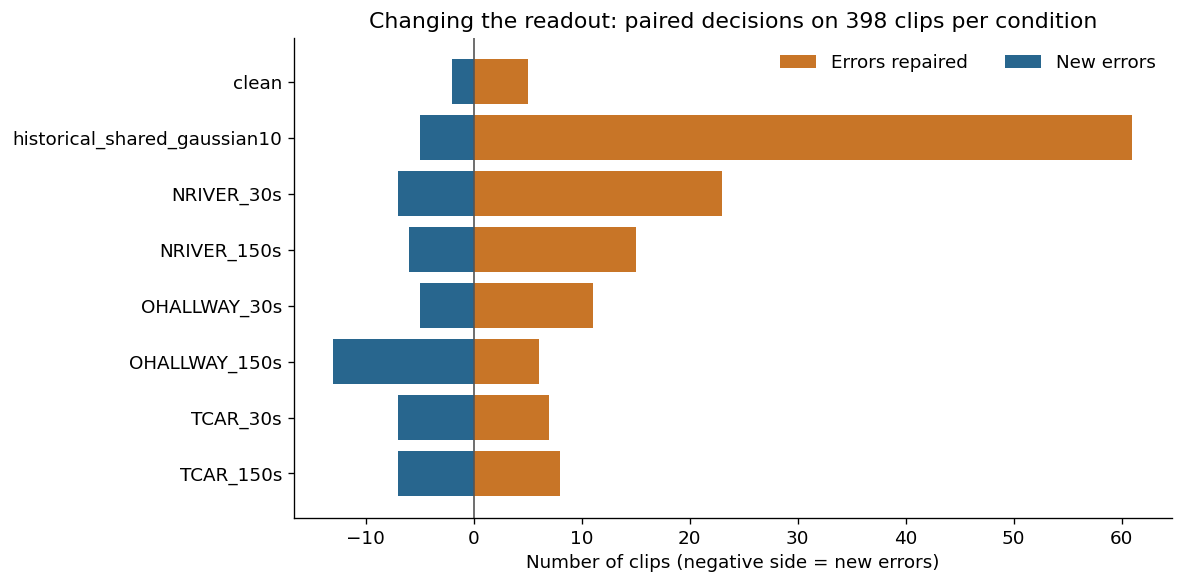

,repairs,new_errors,both_correct,both_wrong
condition,,,,
clean,5,2,361,30
historical_shared_gaussian10,61,5,273,59
NRIVER_30s,23,7,333,35
NRIVER_150s,15,6,340,37
OHALLWAY_30s,11,5,357,25
OHALLWAY_150s,6,13,339,40
TCAR_30s,7,7,357,27
TCAR_150s,8,7,356,27


In [ ]:
frame=transitions.set_index("condition")
fig,ax=plt.subplots(figsize=(10,5));pos=np.arange(len(frame))
ax.barh(pos,frame.repairs,color=COLORS["gaussian_adapted"],label="Errors repaired")
ax.barh(pos,-frame.new_errors,color=COLORS["clean_refit"],label="New errors")
ax.axvline(0,color="#555555",linewidth=1)
ax.set(yticks=pos,yticklabels=frame.index,xlabel="Number of clips (negative side = new errors)",title="Changing the readout: paired decisions on 398 clips per condition")
ax.invert_yaxis();ax.legend(frameon=False,ncol=2)
fig.tight_layout();fig.savefig(DATA/"paired_error_transitions.png",dpi=180,bbox_inches="tight");plt.show()
display(frame[["repairs","new_errors","both_correct","both_wrong"]])

## Takeaways

In [ ]:
if primary.low_pp>0:
    finding="The adapted linear head improves accuracy on this fixed recorded-background panel, with a positive conditional interval. This supports a transferable improvement obtainable without encoder training."
elif primary.high_pp<0:
    finding="The adapted linear head reduces accuracy on this fixed recorded-background panel. Gaussian training did not provide beneficial transfer under this protocol."
else:
    finding="The recorded-background difference is uncertain under the conditional interval. This comparison does not establish an accuracy benefit."
display(Markdown(finding+f" Clean accuracy changes by {clean.delta_pp:+.2f} pp; this is reported jointly and is not a clean noninferiority claim."))
display(Markdown("The result concerns the specified readout intervention and six fixed background segments on historically exposed targets. It does not identify irreversible information loss, isolate pretraining from architecture, establish new-target generalization, or validate field deployment. No extra head, noise policy or encoder fine-tuning was selected after seeing the results. The historical head remains available."))

The recorded-background difference is uncertain under the conditional interval. This comparison does not establish an accuracy benefit. Clean accuracy changes by +0.75 pp; this is reported jointly and is not a clean noninferiority claim.

The result concerns the specified readout intervention and six fixed background segments on historically exposed targets. It does not identify irreversible information loss, isolate pretraining from architecture, establish new-target generalization, or validate field deployment. No extra head, noise policy or encoder fine-tuning was selected after seeing the results. The historical head remains available.